In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

Download the Kaggle Bank Marketing Dataset and use Pandas to load it into a DataFrame named bank_df, then display the first 10 rows and the DataFrame's info().

In [4]:
bank_df = pd.read_csv('C:/Users/lenovo/Desktop/Assignments/Seaborn/banking.csv')
print(bank_df.head(10))
print(bank_df.info())

   age          job   marital          education  default housing loan  \
0   44  blue-collar   married           basic.4y  unknown     yes   no   
1   53   technician   married            unknown       no      no   no   
2   28   management    single  university.degree       no     yes   no   
3   39     services   married        high.school       no      no   no   
4   55      retired   married           basic.4y       no     yes   no   
5   30   management  divorced           basic.4y       no     yes   no   
6   37  blue-collar   married           basic.4y       no     yes   no   
7   39  blue-collar  divorced           basic.9y       no     yes   no   
8   36       admin.   married  university.degree       no      no   no   
9   27  blue-collar    single           basic.4y       no     yes   no   

    contact month day_of_week  ...  campaign  pdays  previous     poutcome  \
0  cellular   aug         thu  ...         1    999         0  nonexistent   
1  cellular   nov         fri

Use Seaborn's countplot to visualize how many customers in the dataset subscribed to a term deposit (column 'y'), and display the plot with appropriate axis labels.

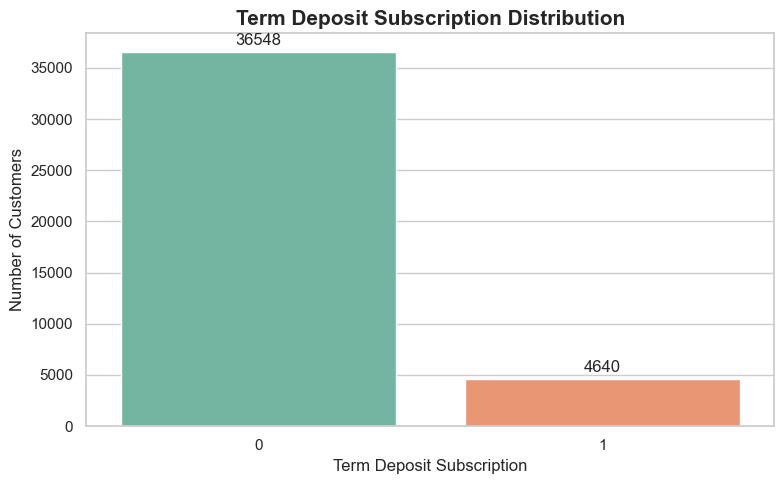

In [5]:
sns.set_theme(style="whitegrid")

# Create figure
plt.figure(figsize=(8, 5))

# Create countplot
ax = sns.countplot(
    data=bank_df,
    x='y',
    hue='y',
    palette='Set2',
    legend=False
)

# Add title and axis labels
plt.title(
    'Term Deposit Subscription Distribution',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Term Deposit Subscription', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# Display count values above bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

# Adjust layout
plt.tight_layout()

# Display plot
plt.show()


Analyze the relationship between customer age and term deposit subscription by creating a Seaborn boxplot with 'y' on the x-axis and 'age' on the y-axis.<br><br><em><strong>Hint:</strong> This helps you see if certain age groups are more likely to subscribe.</em>

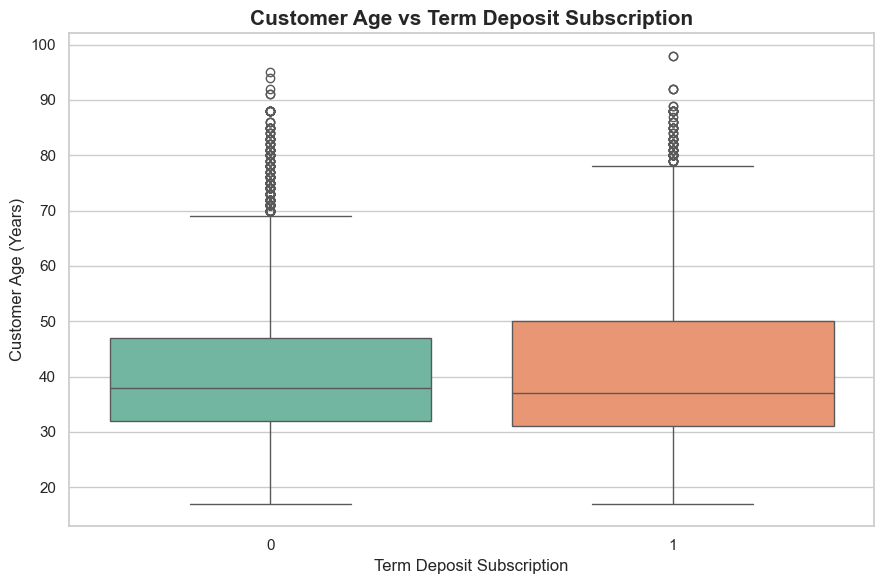

In [6]:
sns.set_theme(style="whitegrid")

# Create figure
plt.figure(figsize=(9, 6))

# Create boxplot
sns.boxplot(
    data=bank_df,
    x='y',
    y='age',
    hue='y',
    palette='Set2',
    legend=False
)

# Add title and axis labels
plt.title(
    'Customer Age vs Term Deposit Subscription',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Term Deposit Subscription', fontsize=12)
plt.ylabel('Customer Age (Years)', fontsize=12)

# Display chart
plt.tight_layout()
plt.show()


Create a bar plot using Seaborn to show the percentage of customers who subscribed to a term deposit for each education level (column 'education').<br><br><em><strong>Hint:</strong> Calculate the percentage for each group before plotting.</em>

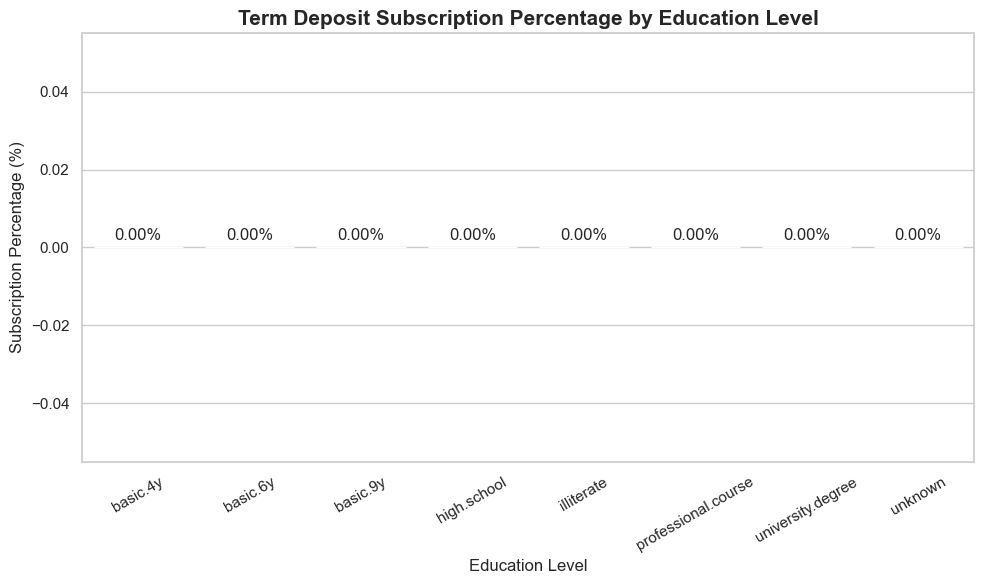

In [7]:
education_percentage = (
    bank_df.groupby('education')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .reset_index(name='Subscription Percentage')
)

# Sort percentages in descending order
education_percentage = education_percentage.sort_values(
    by='Subscription Percentage',
    ascending=False
)

# Set visualization style
sns.set_theme(style="whitegrid")

# Create bar plot
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=education_percentage,
    x='education',
    y='Subscription Percentage',
    hue='education',
    palette='viridis',
    legend=False
)

# Add chart title and labels
plt.title(
    'Term Deposit Subscription Percentage by Education Level',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Subscription Percentage (%)', fontsize=12)

# Display percentage values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=3
    )

plt.xticks(rotation=30)
plt.tight_layout()

# Display chart
plt.show()


Use ChatGPT or Copilot to suggest two additional visualizations that could help a fintech startup like Cred understand which users are most likely to buy a new savings product, then implement one of those visualizations using Seaborn.

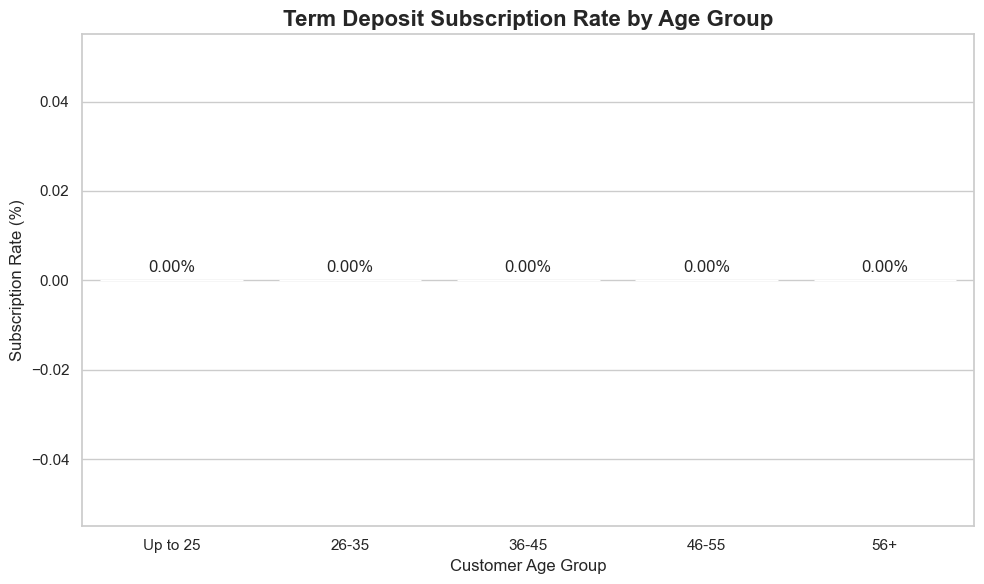

In [8]:
bank_df['age_group'] = pd.cut(
    bank_df['age'],
    bins=[0, 25, 35, 45, 55, float('inf')],
    labels=['Up to 25', '26-35', '36-45', '46-55', '56+']
)

# Calculate subscription percentage by age group
age_subscription = (
    bank_df.groupby('age_group', observed=False)['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .reset_index(name='Subscription Rate')
)

# Set Seaborn theme
sns.set_theme(style='whitegrid', palette='viridis')

# Create bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=age_subscription,
    x='age_group',
    y='Subscription Rate',
    color='teal'
)

# Add chart title and labels
plt.title(
    'Term Deposit Subscription Rate by Age Group',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Customer Age Group', fontsize=12)
plt.ylabel('Subscription Rate (%)', fontsize=12)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=4
    )

plt.tight_layout()

# Save chart
plt.savefig(
    'age_group_subscription.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
